# Income analysis

We use the prepared Eurostat data to compare income across countries, age groups and years. This notebook contains the analysis, visualisations and discussion of the findings, starting with Greece.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter

In [3]:
df_clean = pd.read_csv("../data/processed/ilc_di03_clean.csv")
df_age = pd.read_csv("../data/processed/ilc_di03_age_groups.csv")

In [4]:
# Restore the age order, which is not stored in CSV files.
df_age["age_group"] = pd.Categorical(
    df_age["age_group"],
    categories=["0–17", "18–24", "25–49", "50–64", "65+"],
    ordered=True)

df_clean.shape, df_age.shape

((101948, 14), (23170, 10))

In [5]:
# Create a separate table without changing df_clean.
greece_income = df_clean.loc[
    (df_clean["geo_code"] == "EL")       # Greece
    & (df_clean["sex"] == "T")           # Total population
    & (df_clean["age"] == "TOTAL")       # All ages
    & (df_clean["unit"] == "EUR")
    & df_clean["indicator"].isin(["MEAN_EI", "MED_EI"]),
    ["year", "indicator", "income", "obs_flag"]
].copy()

greece_income.head()

,year,indicator,income,obs_flag
261,2003,MEAN_EI,9675,b
262,2004,MEAN_EI,10199,NaN
263,2005,MEAN_EI,11149,NaN
264,2006,MEAN_EI,11666,NaN
265,2007,MEAN_EI,12130,NaN


### Income reference year

For Greece, income refers to the calendar year before the survey. We keep `year` as the survey year and use `income_year` for the charts, covering 2002–2024.

Source: [ELSTAT, EU-SILC 2025, explanatory notes, p. 14](https://www.statistics.gr/documents/20181/30dc21b1-d0b6-feb9-beca-62e75e6b0d86). We use this definition to align income with historical events.

In [6]:
# Greek income refers to the calendar year before the survey.
greece_income["income_year"] = greece_income["year"] - 1

# Put mean and median in separate columns without calculating new averages.
income_plot = greece_income.pivot(
    index="income_year",
    columns="indicator",
    values="income"
).sort_index()

income_plot.head()

indicator,MEAN_EI,MED_EI
income_year,,
2002,9675,8206
2003,10199,8844
2004,11149,9417
2005,11666,9850
2006,12130,10200


### Government background

Source: [Greek government archive](https://gslegal.gov.gr/kyvernisi/istorika-stoixeia/?sort=time). We use the government dates to define the background periods.

Colours follow the leading party: green for PASOK, blue for New Democracy and red for SYRIZA. Papademos and caretaker governments are grey. Coalition details will appear in the chart notes.

The shading provides historical context and does not establish causation.

In [7]:
background_colors = {
    "PASOK": "#E5F0E7",
    "ND": "#E6EDF8",
    "SYRIZA": "#F6E5E6",
    "Other": "#DDE0E5"}

In [8]:
# Each entry contains: start date, end date, background category.
# The first and last dates are clipped to the chart window.
government_periods = [
    ("2002-01-01", "2004-03-10", "PASOK"),
    ("2004-03-10", "2009-10-06", "ND"),
    ("2009-10-06", "2011-11-11", "PASOK"),
    ("2011-11-11", "2012-05-16", "Other"),  # Papademos
    ("2012-05-16", "2012-06-20", "Other"),  # Pikrammenos, caretaker
    ("2012-06-20", "2015-01-26", "ND"),
    ("2015-01-26", "2015-08-27", "SYRIZA"),
    ("2015-08-27", "2015-09-21", "Other"),  # Thanou, caretaker
    ("2015-09-21", "2019-07-08", "SYRIZA"),
    ("2019-07-08", "2023-05-25", "ND"),
    ("2023-05-25", "2023-06-26", "Other"),  # Sarmas, caretaker
    ("2023-06-26", "2025-01-01", "ND")]

### Memorandum markers

We use the following MoU signature dates for the chart’s vertical markers:

- **3 May 2010:** [European Commission, paragraph 13](https://ec.europa.eu/competition/state_aid/cases/241369/241369_1981018_290_2.pdf).
- **14 March 2012:** [Council of the EU, document 11256/12, paragraph 10](https://register.consilium.europa.eu/pdf/en/12/st11/st11256.en12.pdf).
- **19 August 2015:** [European Commission, “Launch of the programme”](https://economy-finance.ec.europa.eu/eu-financial-assistance/euro-area-countries/financial-assistance-greece_en).

We use these sources only for the signature dates.

In [9]:
# Each entry contains the signature date and its chart label.
# \n places the date on a new line.
memoranda = [
    ("2010-05-03", "1st MoU\n3 May 2010"),
    ("2012-03-14", "2nd MoU\n14 Mar 2012"),
    ("2015-08-19", "3rd MoU\n19 Aug 2015")]

### Coalition labels

The notes identify ND-led coalitions in 2012–2015 and SYRIZA–ANEL in January–August 2015 and September 2015–January 2019.

Sources: [ECA programme timeline](https://op.europa.eu/webpub/eca/special-reports/greek-crisis-17-2017/en/), [IPU, January 2015 election](https://data.ipu.org/election-summary/HTML/2125_15_Jan.htm), and [European Parliament, Greece country sheet, p. 35](https://www.europarl.europa.eu/pdfs/news/expert/2019/5/background/20190516BKG51011/20190516BKG51011_en.pdf#page=35).

These sources support the coalition labels. Government boundaries follow the Greek government archive cited above.

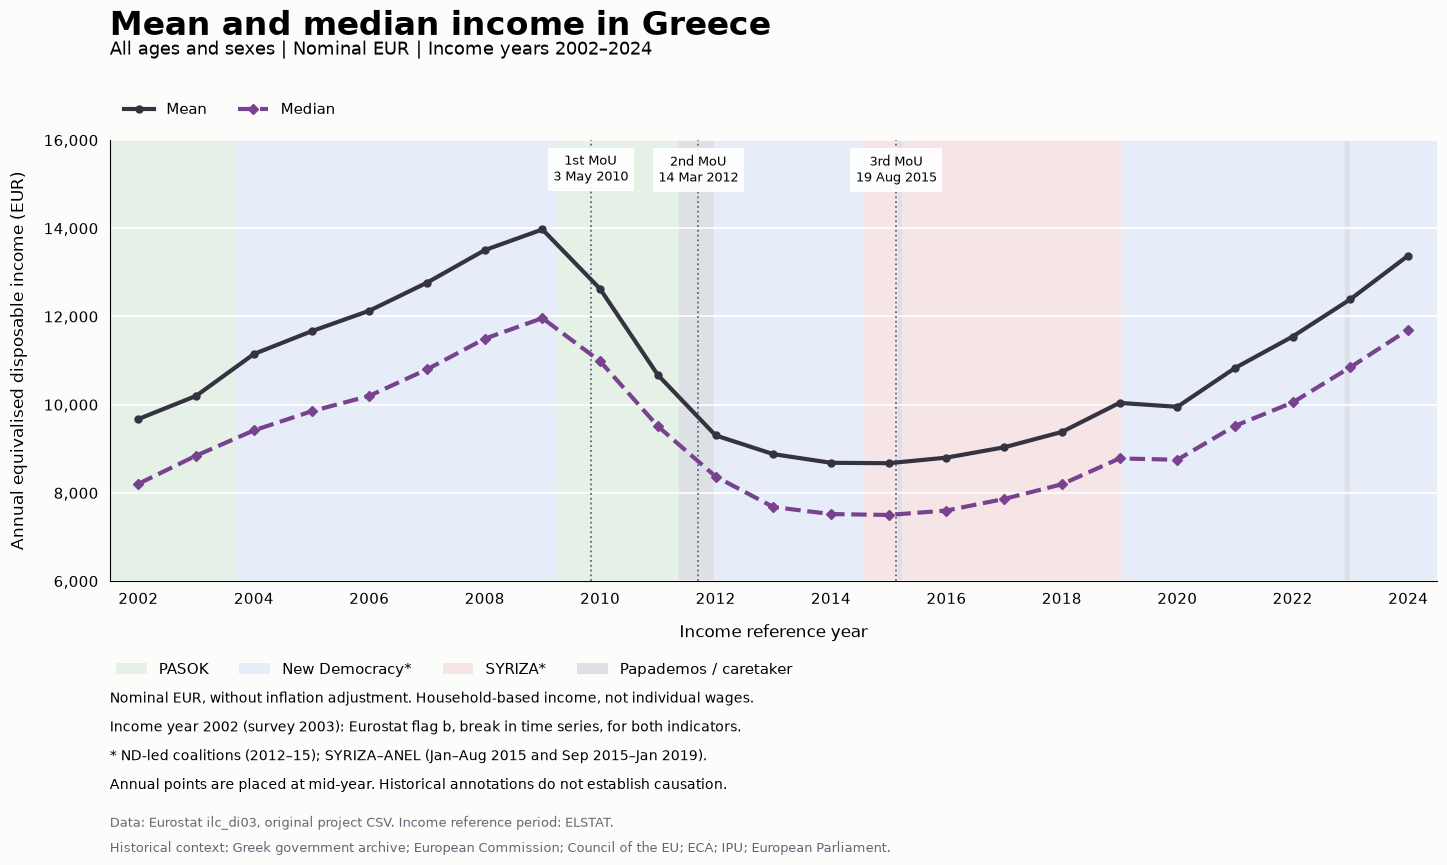

In [10]:
# Place annual observations at mid-year for plotting.
# This is a display convention, not an exact measurement date.
plot_dates = pd.to_datetime(income_plot.index.astype(str) + "-07-01")

fig, ax = plt.subplots(figsize=(15, 9), facecolor="#FCFCFA")

# Leave space for the title, legends and notes.
fig.subplots_adjust(left=0.08, right=0.965, top=0.82, bottom=0.33)

# Draw the government backgrounds behind the income lines.
for start, end, party in government_periods:
    ax.axvspan(
        pd.Timestamp(start), pd.Timestamp(end),
        color=background_colors[party], zorder=0)

ax.plot(
    plot_dates, income_plot["MEAN_EI"],
    color="#34333F", linestyle="-", linewidth=3,
    marker="o", markersize=5, label="Mean", zorder=3)

ax.plot(
    plot_dates, income_plot["MED_EI"],
    color="#79428E", linestyle="--", linewidth=3,
    marker="D", markersize=5, label="Median", zorder=3)

for date, label in memoranda:
    date = pd.Timestamp(date)
    ax.axvline(
        date, color="#626875", linestyle=":", linewidth=1.3, zorder=2)

    # Keep the date on the x-axis and the label at 97% of the chart height.
    ax.text(
        date, 0.97, label, transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=9.5,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
        zorder=4)

# Show a tick every two income years.
ax.set_xticks(plot_dates[::2])
ax.set_xticklabels(income_plot.index[::2])

ax.set_xlim(pd.Timestamp("2002-01-01"), pd.Timestamp("2025-01-01"))
ax.set_ylim(6000, 16000)
ax.set_yticks(range(6000, 16001, 2000))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.set_xlabel("Income reference year", fontsize=12, labelpad=12)
ax.set_ylabel(
    "Annual equivalised disposable income (EUR)",
    fontsize=12, labelpad=12)

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(axis="y", color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.02),
    ncol=2, frameon=False, fontsize=11)

fig.suptitle(
    "Mean and median income in Greece",
    x=0.08, y=0.965, ha="left", fontsize=24, fontweight="bold")
fig.text(
    0.08, 0.915,
    "All ages and sexes | Nominal EUR | Income years 2002–2024",
    fontsize=13)

# Use coloured boxes to explain the government backgrounds.
government_legend = [
    Patch(facecolor=background_colors["PASOK"], label="PASOK"),
    Patch(facecolor=background_colors["ND"], label="New Democracy*"),
    Patch(facecolor=background_colors["SYRIZA"], label="SYRIZA*"),
    Patch(facecolor=background_colors["Other"], label="Papademos / caretaker")]

fig.legend(
    handles=government_legend, loc="upper left",
    bbox_to_anchor=(0.075, 0.255),
    ncol=4, frameon=False, fontsize=11)

# Figure coordinates run from 0 to 1.
# These positions place the notes below the chart.
fig.text(
    0.08, 0.195,
    "Nominal EUR, without inflation adjustment. Household-based income, not individual wages.",
    fontsize=10)
fig.text(
    0.08, 0.163,
    "Income year 2002 (survey 2003): Eurostat flag b, break in time series, for both indicators.",
    fontsize=10)
fig.text(
    0.08, 0.131,
    "* ND-led coalitions (2012–15); SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).",
    fontsize=10)
fig.text(
    0.08, 0.099,
    "Annual points are placed at mid-year. Historical annotations do not establish causation.",
    fontsize=10)
fig.text(
    0.08, 0.057,
    "Data: Eurostat ilc_di03, original project CSV. Income reference period: ELSTAT.",
    fontsize=9, color="#626875")
fig.text(
    0.08, 0.029,
    "Historical context: Greek government archive; European Commission; "
    "Council of the EU; ECA; IPU; European Parliament.",
    fontsize=9, color="#626875")

fig.savefig(
    "../reports/figures/greece_income_mean_median.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

In [11]:
# idxmax/idxmin return the year; max/min return the income value.
# income_plot is sorted by year, so its last row is the latest year.
income_summary = pd.DataFrame({
    "Peak year": income_plot.idxmax(),
    "Peak income (EUR)": income_plot.max(),
    "Lowest year": income_plot.idxmin(),
    "Lowest income (EUR)": income_plot.min(),
    "Latest year": income_plot.index[-1],
    "Latest income (EUR)": income_plot.iloc[-1]})

income_summary = income_summary.rename(index={"MEAN_EI": "Mean", "MED_EI": "Median"})

income_summary

,Peak year,Peak income (EUR),Lowest year,Lowest income (EUR),Latest year,Latest income (EUR)
indicator,,,,,,
Mean,2009,13974,2015,8673,2024,13381
Median,2009,11963,2015,7500,2024,11700


### Mean–median income gap

Greece, all ages and sexes, equivalised disposable income in nominal EUR.

**Gap (%) = (mean − median) / median × 100**

| Income year | Mean (€) | Median (€) | Mean above median |
|---|---:|---:|---:|
| 2009 | 13,974 | 11,963 | 16.81% |
| 2015 | 8,673 | 7,500 | 15.64% |
| 2024 | 13,381 | 11,700 | 14.37% |

Very high incomes can pull the mean upwards, while the median is less sensitive to their size ([NIST](https://www.itl.nist.gov/div898/handbook/eda/section3/eda351.htm)). This is a plausible explanation, but these summaries cannot show how many people have low or very high incomes.

Employment, capital income, taxes and transfers also shape income distribution ([OECD, 2012](https://www.oecd.org/content/dam/oecd/en/publications/reports/2012/01/less-income-inequality-and-more-growth-are-they-compatible-part-1-mapping-income-inequality-across-the-oecd_g17a20b6/5k9h297wxbnr-en.pdf)). Their contribution to the Greek gap remains unverified.

In [12]:
# Compare the end of each period with its starting value.
income_changes = pd.DataFrame({
    "2009–2015 (EUR)": income_plot.loc[2015] - income_plot.loc[2009],
    "2009–2015 (%)": (income_plot.loc[2015] / income_plot.loc[2009] - 1) * 100,
    "2015–2024 (EUR)": income_plot.loc[2024] - income_plot.loc[2015],
    "2015–2024 (%)": (income_plot.loc[2024] / income_plot.loc[2015] - 1) * 100,
    "2009–2024 (EUR)": income_plot.loc[2024] - income_plot.loc[2009],
    "2009–2024 (%)": (income_plot.loc[2024] / income_plot.loc[2009] - 1) * 100})

income_changes = income_changes.rename(
    index={"MEAN_EI": "Mean", "MED_EI": "Median"})

# Round only the displayed result.
income_changes.round(2)

,2009–2015 (EUR),2009–2015 (%),2015–2024 (EUR),2015–2024 (%),2009–2024 (EUR),2009–2024 (%)
indicator,,,,,,
Mean,-5301,-37.93,4708,54.28,-593,-4.24
Median,-4463,-37.31,4200,56.00,-263,-2.20


Nominal income changes in Greece

For all ages and sexes, mean equivalised disposable income fell 37.93% between income years 2009 and 2015; median income fell 37.31%.

Between 2015 and 2024, mean income increased 54.28% and median income 56.00%. Despite this recovery, both remained below their 2009 peaks: mean by €593 (4.24%) and median by €263 (2.20%).

These are cumulative changes in nominal EUR. They do not account for inflation or establish a recovery in purchasing power.

Income in Greece by age group

Mean and median equivalised disposable income for five age groups, all sexes, in nominal EUR.

Legend: Colours identify age groups. Mean uses solid lines; median uses dashed lines. Both panels share the same income scale.

Notes: Income years 2002–2024 correspond to surveys 2003–2025 (ELSTAT, p. 14). Income year 2002 retains flag b (break in time series) for every group and both indicators. Amounts are not adjusted for inflation.

Government shading and MoU markers follow the sources documented above.

In [13]:
greece_age = df_age.loc[
    (df_age["geo_code"] == "EL")
    & (df_age["sex"] == "T")
    & (df_age["unit"] == "EUR")
    & df_age["indicator"].isin(["MEAN_EI", "MED_EI"])].copy()

greece_age["income_year"] = greece_age["year"] - 1

In [14]:
# Reshape the published values without calculating new means or medians.
age_mean = greece_age.loc[greece_age["indicator"] == "MEAN_EI"].pivot(
    index="income_year", columns="age_group", values="income").sort_index()

age_median = greece_age.loc[greece_age["indicator"] == "MED_EI"].pivot(
    index="income_year", columns="age_group", values="income").sort_index()

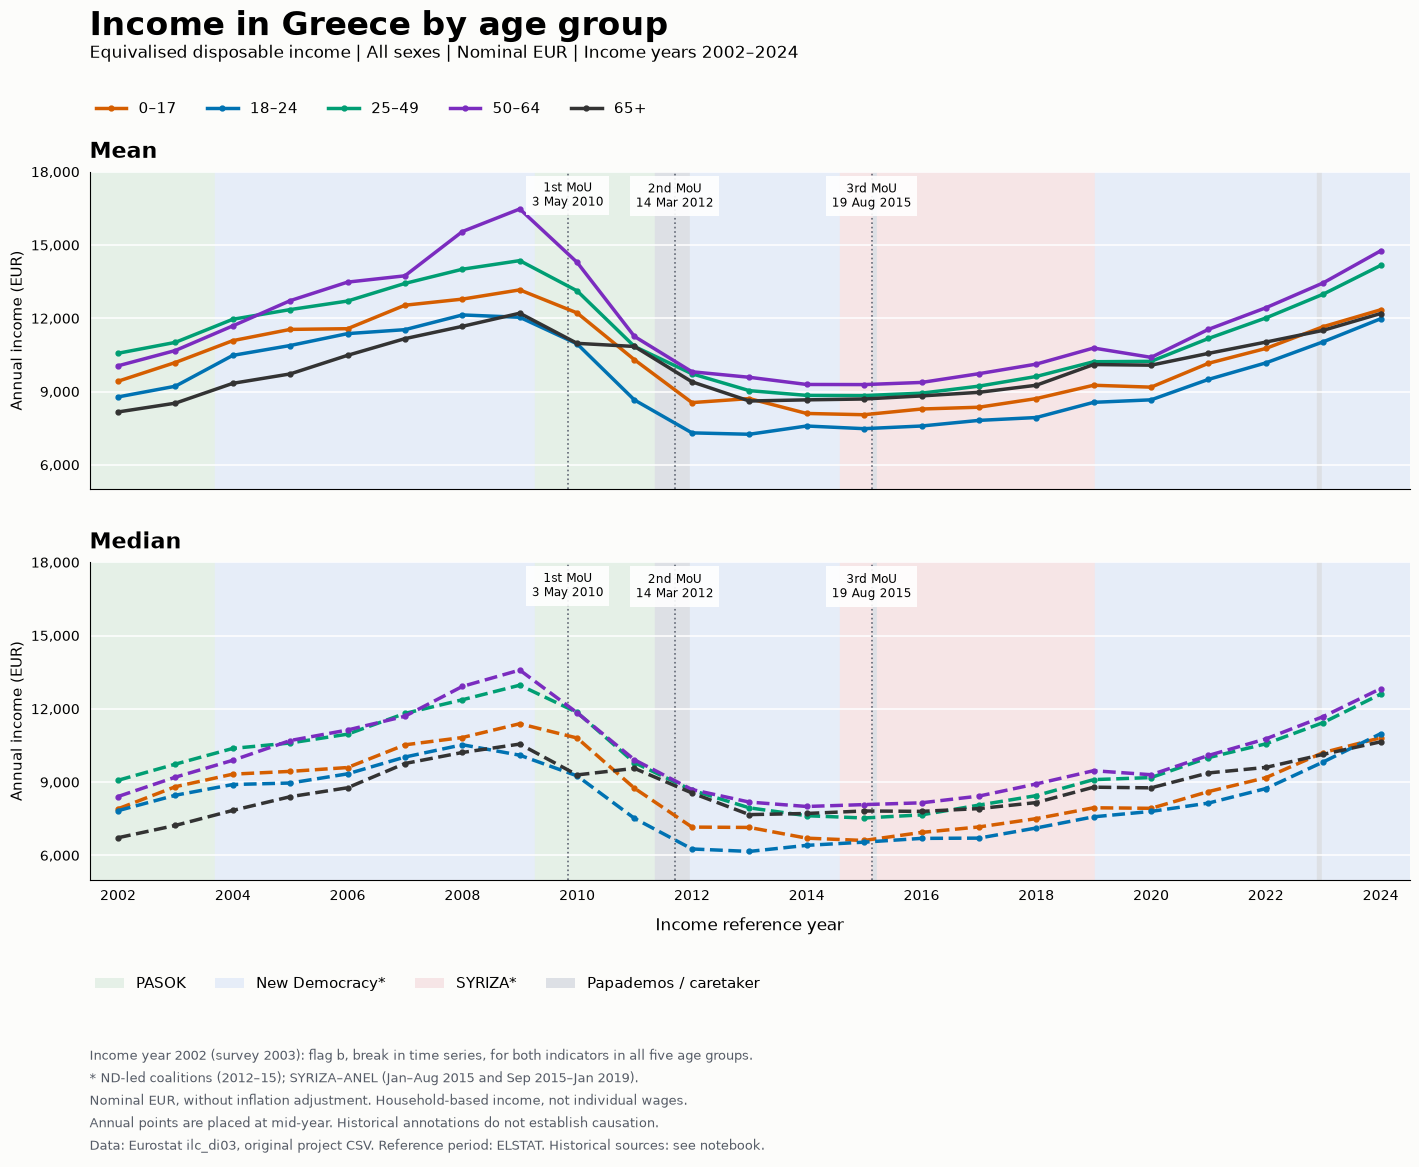

In [15]:
age_colors = {
    "0–17": "#D55E00",
    "18–24": "#0072B2",
    "25–49": "#009E73",
    "50–64": "#7B2CBF",
    "65+": "#333333"}

# Mid-year placement is a plotting convention, not a measurement date.
age_dates = pd.to_datetime(age_mean.index.astype(str) + "-07-01")

# Both panels use the same time axis and income scale.
fig, axes = plt.subplots(
    2, 1, figsize=(15, 12), sharex=True, sharey=True, facecolor="#FCFCFA")
fig.subplots_adjust(
    left=0.09, right=0.97, top=0.84, bottom=0.25, hspace=0.23)

# Pair each panel with its table, title and line style.
for ax, data, title, style in [
    (axes[0], age_mean, "Mean", "-"),
    (axes[1], age_median, "Median", "--")
]:
    for start, end, party in government_periods:
        ax.axvspan(
            pd.Timestamp(start), pd.Timestamp(end),
            color=background_colors[party], zorder=0
        )

    for group, color in age_colors.items():
        ax.plot(
            age_dates, data[group],
            color=color, linestyle=style, linewidth=2.5,
            marker="o", markersize=3.5, label=group, zorder=3
        )

    for date, label in memoranda:
        date = pd.Timestamp(date)
        ax.axvline(
            date, color="#626875", linestyle=":", linewidth=1.2
        )

        # Keep the label near the top, regardless of the income values.
        ax.text(
            date, 0.97, label,
            transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8.5,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.9,
            },
            zorder=4
        )

    ax.set_title(
        title, loc="left", fontsize=16, fontweight="bold", pad=10
    )
    ax.set_ylim(5000, 18000)
    ax.set_yticks(range(6000, 18001, 3000))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_ylabel("Annual income (EUR)", fontsize=11)
    ax.grid(axis="y", color="white", linewidth=1.1)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", labelsize=10, length=0, pad=7)

axes[1].set_xticks(age_dates[::2])
axes[1].set_xticklabels(age_mean.index[::2])
axes[1].set_xlim(pd.Timestamp("2002-01-01"), pd.Timestamp("2025-01-01"))
axes[1].set_xlabel("Income reference year", fontsize=12, labelpad=10)

fig.suptitle(
    "Income in Greece by age group",
    x=0.09, y=0.975, ha="left", fontsize=24, fontweight="bold")
fig.text(
    0.09, 0.935,
    "Equivalised disposable income | All sexes | Nominal EUR | "
    "Income years 2002–2024",
    fontsize=12)

# Use one age-group legend for both panels.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper left", bbox_to_anchor=(0.085, 0.91),
    ncol=5, frameon=False, fontsize=11)

# Reuse the government legend from the previous chart.
fig.legend(
    handles=government_legend,
    loc="upper left", bbox_to_anchor=(0.085, 0.18),
    ncol=4, frameon=False, fontsize=10.5)

fig.text(
    0.09, 0.025,
    "Income year 2002 (survey 2003): flag b, break in time series, "
    "for both indicators in all five age groups.\n"
    "* ND-led coalitions (2012–15); "
    "SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).\n"
    "Nominal EUR, without inflation adjustment. "
    "Household-based income, not individual wages.\n"
    "Annual points are placed at mid-year. "
    "Historical annotations do not establish causation.\n"
    "Data: Eurostat ilc_di03, original project CSV. "
    "Reference period: ELSTAT. Historical sources: see notebook.",
    fontsize=9, linespacing=1.8, color="#555B66")

# Save the figure before displaying it.
fig.savefig(
    "../reports/figures/greece_income_by_age_mean_median.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

In [16]:
# Put each age group and indicator on a separate row.
age_comparison = greece_age.loc[
    greece_age["income_year"].isin([2009, 2015, 2024])
].pivot(
    index=["age_group", "indicator"],
    columns="income_year",
    values="income"
).sort_index()

# Each percentage uses the first year of the period as its base.
age_comparison["2009–2015 (%)"] = (age_comparison[2015] / age_comparison[2009] - 1) * 100

age_comparison["2015–2024 (%)"] = (age_comparison[2024] / age_comparison[2015] - 1) * 100

age_comparison["2009–2024 (%)"] = (age_comparison[2024] / age_comparison[2009] - 1) * 100

# Rename only the indicator level of the row index.
age_comparison = age_comparison.rename(
    index={"MEAN_EI": "Mean", "MED_EI": "Median"},
    level="indicator")

age_comparison.columns.name = None
age_comparison.round(2)

2009  2015   2024  2009–2015 (%)  2015–2024 (%)  \
age_group indicator                                                     
0–17      Mean       13163  8051  12347         -38.84          53.36   
          Median     11389  6608  10813         -41.98          63.63   
18–24     Mean       12041  7480  11981         -37.88          60.17   
          Median     10100  6540  10981         -35.25          67.91   
25–49     Mean       14361  8835  14164         -38.48          60.32   
          Median     12967  7529  12600         -41.94          67.35   
50–64     Mean       16476  9285  14762         -43.65          58.99   
          Median     13586  8077  12824         -40.55          58.77   
65+       Mean       12208  8695  12195         -28.78          40.25   
          Median     10555  7816  10648         -25.95          36.23   

                     2009–2024 (%)  
age_group indicator                 
0–17      Mean               -6.20  
          Median             -5.06  
18–24     Mean               -0.50  
          Median              8.72  
25–49     Mean               -1.37  
          Median             -2.83  
50–64     Mean              -10.40  
          Median             -5.61  
65+       Mean               -0.11  
          Median              0.88

### Income changes by age group in Greece

Between 2009 and 2015, the largest percentage fall in mean income was among people aged **50–64 (43.65%)**. Median income fell by approximately **42%** in both the **0–17** and **25–49** groups.

In 2024, mean income remained below its 2009 level in all five groups. Median income exceeded its 2009 level for **18–24 (+8.72%)** and **65+ (+0.88%)**.

These comparisons use fixed income years, rather than each group’s own peak and lowest point. Amounts remain nominal, without inflation adjustment.

### Reading the recovery figures

The **65+** group had the smallest percentage declines between 2009 and 2015: **28.78% in mean** and **25.95% in median income**. Its smaller increases after 2015 should be considered alongside these smaller initial losses.

Percentage falls and rebounds use different starting values and cannot be added. For **50–64**, mean income fell **43.65%**, then rose **58.99%**, yet remained **10.40% below its 2009 level** in 2024.

These comparisons remain in nominal EUR, without inflation adjustment.

In [17]:
hicp_greece = pd.read_csv("../data/processed/hicp_greece.csv")

# Check coverage against the income years used in this analysis.
missing_years = sorted(set(greece_income["income_year"]) - set(hicp_greece["TIME_PERIOD"]))
print("Income years without HICP:", missing_years)

Income years without HICP: []


### Linking income and prices

We use Greece’s annual average all-items HICP from [Eurostat (`prc_hicp_ainr`)](https://ec.europa.eu/eurostat/databrowser/view/prc_hicp_ainr/default/table?lang=en).

The HICP calendar year is matched to `income_year`. The same national price index is used for all age groups. Income flags and HICP flags are kept separately.

The index reference period is **2025=100** ([HICP metadata](https://ec.europa.eu/eurostat/cache/metadata/en/prc_hicp_esms.htm)).

In [18]:
# HICP calendar years match the income reference years directly.
hicp_for_merge = hicp_greece.rename(columns={
    "TIME_PERIOD": "income_year",
    "OBS_VALUE": "hicp_index",
    "OBS_FLAG": "hicp_flag"})

In [19]:
# Add the price index while preserving the original income flags.
greece_income_hicp = greece_income.merge(
    hicp_for_merge,
    on="income_year",
    how="left")

greece_age_hicp = greece_age.merge(
    hicp_for_merge,
    on="income_year",
    how="left")

display(greece_income_hicp.head())
display(greece_age_hicp.head())

,year,indicator,income,obs_flag,income_year,hicp_index,hicp_flag
0,2003,MEAN_EI,9675,b,2002,62.30,NaN
1,2004,MEAN_EI,10199,NaN,2003,64.45,NaN
2,2005,MEAN_EI,11149,NaN,2004,66.40,NaN
3,2006,MEAN_EI,11666,NaN,2005,68.72,NaN
4,2007,MEAN_EI,12130,NaN,2006,70.99,NaN


,geo_code,geo_name,year,age,age_group,sex,indicator,unit,income,obs_flag,income_year,hicp_index,hicp_flag
0,EL,Greece,2003,Y18-24,18–24,T,MEAN_EI,EUR,8779,b,2002,62.30,NaN
1,EL,Greece,2004,Y18-24,18–24,T,MEAN_EI,EUR,9218,NaN,2003,64.45,NaN
2,EL,Greece,2005,Y18-24,18–24,T,MEAN_EI,EUR,10482,NaN,2004,66.40,NaN
3,EL,Greece,2006,Y18-24,18–24,T,MEAN_EI,EUR,10885,NaN,2005,68.72,NaN
4,EL,Greece,2007,Y18-24,18–24,T,MEAN_EI,EUR,11372,NaN,2006,70.99,NaN


### Income in constant 2024 EUR

We adjust income using Greece’s annual average all-items HICP:

**Income in 2024 EUR = nominal income × HICP for 2024 / HICP for the income year.**

This expresses all amounts at the 2024 price level. Original nominal values and observation flags are retained.

[Formula reference: BLS](https://www.bls.gov/cpi/factsheets/income.htm), applied here to the Greek HICP series.

In [20]:
# Get the annual HICP index for the reference year.
hicp_2024 = hicp_greece.loc[hicp_greece["TIME_PERIOD"] == 2024, "OBS_VALUE"].iloc[0]

In [21]:
# Add real income while keeping the original nominal income.
greece_income_hicp["income_real_2024"] = (greece_income_hicp["income"] * hicp_2024 / greece_income_hicp["hicp_index"])

greece_age_hicp["income_real_2024"] = (greece_age_hicp["income"] * hicp_2024 / greece_age_hicp["hicp_index"])

# Compare nominal and real amounts for the selected income years.
display(
    greece_income_hicp.loc[
        greece_income_hicp["income_year"].isin([2009, 2015, 2024]),
        ["income_year", "indicator", "income", "income_real_2024"],
    ].sort_values(["income_year", "indicator"]).round(2))

,income_year,indicator,income,income_real_2024
7,2009,MEAN_EI,13974,17583.29
30,2009,MED_EI,11963,15052.87
13,2015,MEAN_EI,8673,10347.76
36,2015,MED_EI,7500,8948.26
22,2024,MEAN_EI,13381,13381.00
45,2024,MED_EI,11700,11700.00


In [22]:
rows = []
# Calculate mean and median changes separately.
for indicator, label in [("MEAN_EI", "Mean"), ("MED_EI", "Median")]:
    data = greece_income_hicp.loc[
        greece_income_hicp["indicator"] == indicator
    ].set_index("income_year")

    for start, end in [(2009, 2015), (2015, 2024), (2009, 2024)]:
        # Compare the end of each period with its starting value.
        nominal_change = (
            data.loc[end, "income"] / data.loc[start, "income"] - 1 ) * 100

        real_change = (
            data.loc[end, "income_real_2024"]
            / data.loc[start, "income_real_2024"] - 1 ) * 100

        rows.append({
            "Indicator": label,
            "Period": f"{start}–{end}",
            "Nominal (%)": nominal_change,
            "Real (%)": real_change
        })

income_change_comparison = pd.DataFrame(rows)
display(income_change_comparison.round(2))

,Indicator,Period,Nominal (%),Real (%)
0,Mean,2009–2015,-37.93,-41.15
1,Mean,2015–2024,54.28,29.31
2,Mean,2009–2024,-4.24,-23.90
3,Median,2009–2015,-37.31,-40.55
4,Median,2015–2024,56.00,30.75
5,Median,2009–2024,-2.20,-22.27


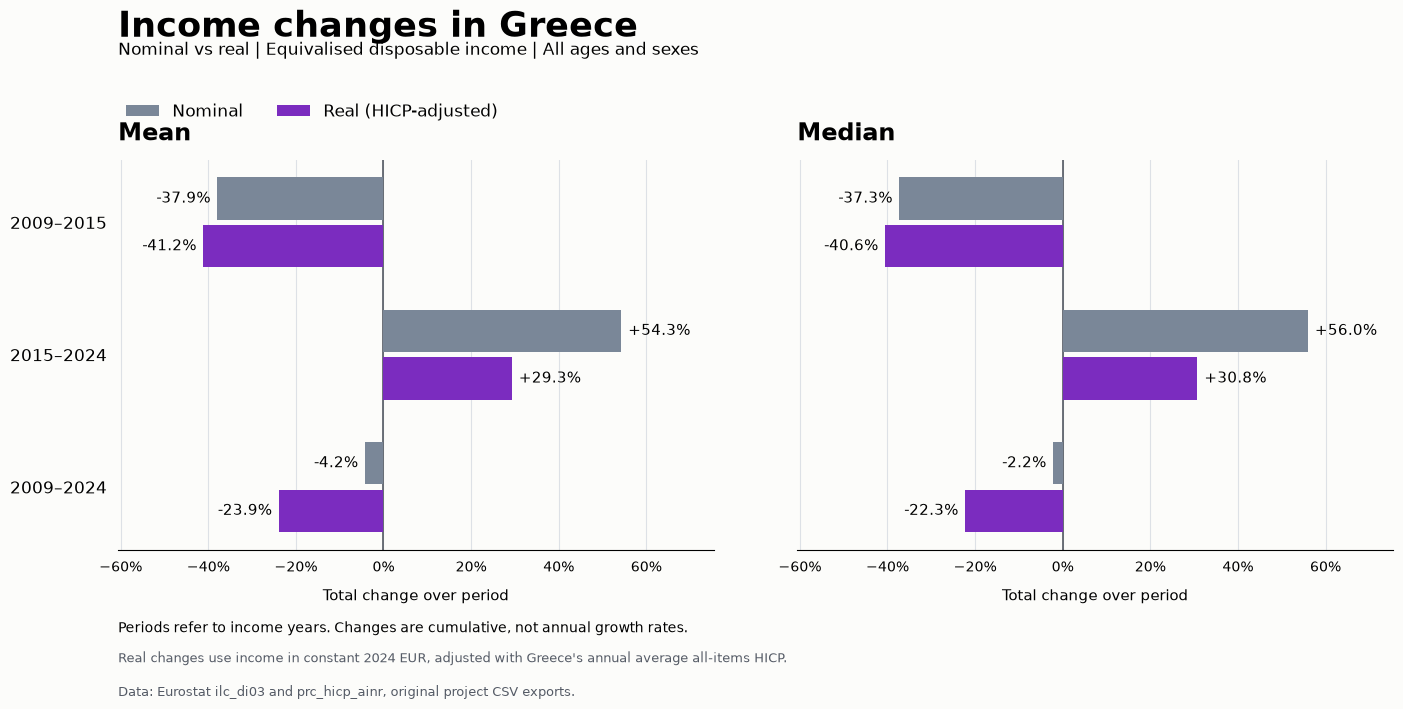

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharex=True, sharey=True, facecolor="#FCFCFA")
fig.subplots_adjust(left=0.12, right=0.97, top=0.76, bottom=0.24, wspace=0.14)

# Place the three periods from top to bottom.
positions = [2, 1, 0]

for ax, indicator in [(axes[0], "Mean"), (axes[1], "Median")]:
    panel_data = income_change_comparison.loc[
        income_change_comparison["Indicator"] == indicator]

    # Offset the bars so nominal and real changes appear as a pair.
    nominal_bars = ax.barh(
        [p + 0.18 for p in positions],
        panel_data["Nominal (%)"],
        height=0.32, color="#7A8798", label="Nominal", zorder=3)
    real_bars = ax.barh(
        [p - 0.18 for p in positions],
        panel_data["Real (%)"],
        height=0.32, color="#7B2CBF",
        label="Real (HICP-adjusted)", zorder=3)

    # Show signed percentages at the ends of the bars.
    ax.bar_label(nominal_bars, fmt="%+.1f%%", padding=5, fontsize=11)
    ax.bar_label(real_bars, fmt="%+.1f%%", padding=5, fontsize=11)

    ax.set_title(indicator, loc="left", fontsize=17, fontweight="bold", pad=14)
    ax.set_yticks(positions)
    ax.set_yticklabels(panel_data["Period"], fontsize=12)
    ax.set_xlabel("Total change over period", fontsize=11, labelpad=10)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

    ax.axvline(0, color="#454B55", linewidth=1.1)
    ax.grid(axis="x", color="#DDE1E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_facecolor("#FCFCFA")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=8)

    # Leave space for labels outside positive and negative bars.
    ax.margins(x=0.20)

fig.suptitle(
    "Income changes in Greece",
    x=0.12, y=0.96, ha="left", fontsize=25, fontweight="bold")
fig.text(
    0.12, 0.90,
    "Nominal vs real | Equivalised disposable income | All ages and sexes",
    fontsize=12)

# Use one legend for both panels.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper left", bbox_to_anchor=(0.115, 0.855),
    ncol=2, frameon=False, fontsize=12)

fig.text(
    0.12, 0.13,
    "Periods refer to income years. Changes are cumulative, not annual growth rates.",
    fontsize=10)
fig.text(
    0.12, 0.09,
    "Real changes use income in constant 2024 EUR, adjusted with Greece's annual average all-items HICP.",
    fontsize=9.5, color="#555B66")
fig.text(
    0.12, 0.045,
    "Data: Eurostat ilc_di03 and prc_hicp_ainr, original project CSV exports.",
    fontsize=9, color="#555B66")

# Save before displaying the figure.
fig.savefig(
    "../reports/figures/greece_income_nominal_real_changes.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

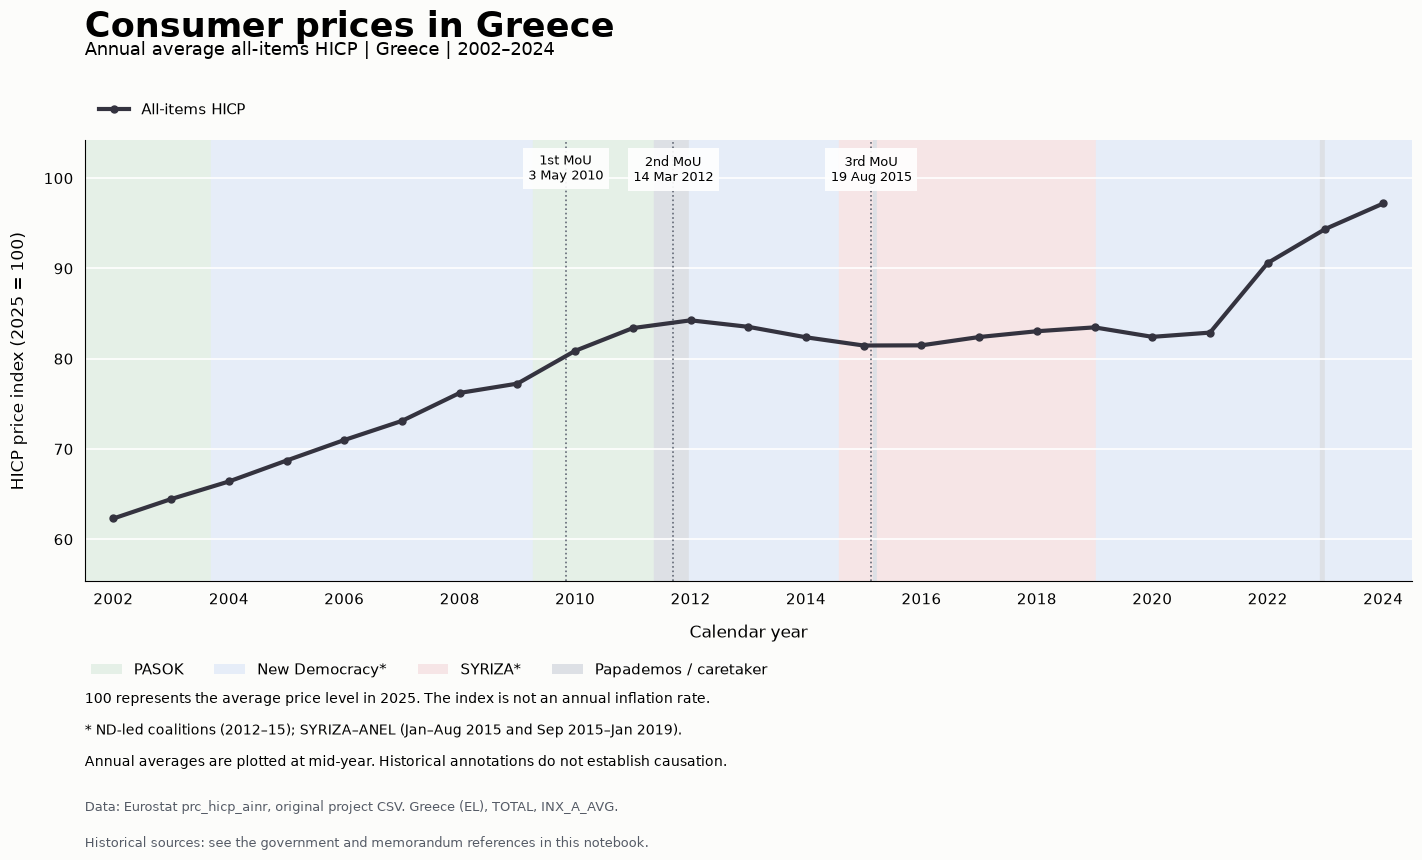

In [24]:
price_data = hicp_greece.sort_values("TIME_PERIOD")

# Annual averages are placed at mid-year for the historical annotations.
price_dates = pd.to_datetime(price_data["TIME_PERIOD"].astype(str) + "-07-01")

fig, ax = plt.subplots(figsize=(15, 9), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.08, right=0.965, top=0.82, bottom=0.33)

for start, end, party in government_periods:
    ax.axvspan(
        pd.Timestamp(start), pd.Timestamp(end),
        color=background_colors[party], zorder=0)

ax.plot(
    price_dates, price_data["OBS_VALUE"],
    color="#34333F", linewidth=3,
    marker="o", markersize=5, label="All-items HICP", zorder=3)

# Add the memorandum markers using the dates already documented.
for date, label in memoranda:
    date = pd.Timestamp(date)

    ax.axvline(
        date, color="#626875", linestyle=":",
        linewidth=1.2, zorder=2)

    # Keep the date on the x-axis and the label near the chart's top.
    ax.text(
        date, 0.97, label,
        transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
        zorder=4)

# Show a tick every two calendar years.
ax.set_xticks(price_dates.iloc[::2])
ax.set_xticklabels(price_data["TIME_PERIOD"].iloc[::2])
ax.set_xlim(pd.Timestamp("2002-01-01"), pd.Timestamp("2025-01-01"))
ax.margins(y=0.20)

ax.set_xlabel("Calendar year", fontsize=12, labelpad=12)
ax.set_ylabel("HICP price index (2025 = 100)", fontsize=12, labelpad=12)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(axis="y", color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False, fontsize=11)

fig.suptitle(
    "Consumer prices in Greece",
    x=0.08, y=0.965, ha="left",
    fontsize=25, fontweight="bold")
fig.text(
    0.08, 0.915,
    "Annual average all-items HICP | Greece | 2002–2024",
    fontsize=13)

# Reuse the government legend from the income chart.
fig.legend(
    handles=government_legend,
    loc="upper left", bbox_to_anchor=(0.075, 0.255),
    ncol=4, frameon=False, fontsize=11)

fig.text(
    0.08, 0.195,
    "100 represents the average price level in 2025. "
    "The index is not an annual inflation rate.",
    fontsize=10)
fig.text(
    0.08, 0.16,
    "* ND-led coalitions (2012–15); "
    "SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).",
    fontsize=10)
fig.text(
    0.08, 0.125,
    "Annual averages are plotted at mid-year. "
    "Historical annotations do not establish causation.",
    fontsize=10)
fig.text(
    0.08, 0.075,
    "Data: Eurostat prc_hicp_ainr, original project CSV. "
    "Greece (EL), TOTAL, INX_A_AVG.",
    fontsize=9, color="#555B66")
fig.text(
    0.08, 0.035,
    "Historical sources: see the government and memorandum references "
    "in this notebook.",
    fontsize=9, color="#555B66")

# Save the completed figure before displaying it.
fig.savefig(
    "../reports/figures/greece_hicp_price_index.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Housing cost pressure in Greece

The housing cost overburden rate is the percentage of people living in households whose housing costs exceed 40% of disposable income, both net of housing allowances.

We start with all ages and income groups. Years refer to the survey year.

Sources: [Eurostat definition](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=Glossary:Housing_cost_overburden_rate) and [reference periods](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=EU_statistics_on_income_and_living_conditions_(EU-SILC)_methodology_-_housing_conditions#Reference_period).

In [25]:
housing_data = pd.read_csv("../data/processed/ilc_lvho07a_greece.csv")

In [26]:
# Select the published rate for the total Greek population.
housing_total = housing_data.loc[
    (housing_data["geo_code"] == "EL")
    & (housing_data["sex"] == "T")
    & (housing_data["age"] == "TOTAL")
    & (housing_data["rskpovth"] == "TOTAL")
    & (housing_data["unit"] == "PC"),
    ["year", "housing_overburden_rate", "obs_flag"]
].copy().sort_values("year")

In [27]:
# Check for absent years within the available analysis period.
missing_housing_years = sorted(set(range(2004, 2026)) - set(housing_total["year"]))

print("Missing years:", missing_housing_years)
display(housing_total)

Missing years: []


,year,housing_overburden_rate,obs_flag
748,2004,24.7,NaN
749,2005,22.7,NaN
750,2006,24.6,NaN
751,2007,15.8,NaN
752,2008,22.2,NaN
753,2009,21.8,NaN
754,2010,18.1,NaN
755,2011,24.2,NaN
756,2012,33.1,NaN
757,2013,36.9,NaN


ND shading continues through 2025 ([Prime Minister’s Office, 11 December 2025](https://www.primeminister.gr/2025/12/11/37583)). The date 1 January 2026 is the chart boundary.

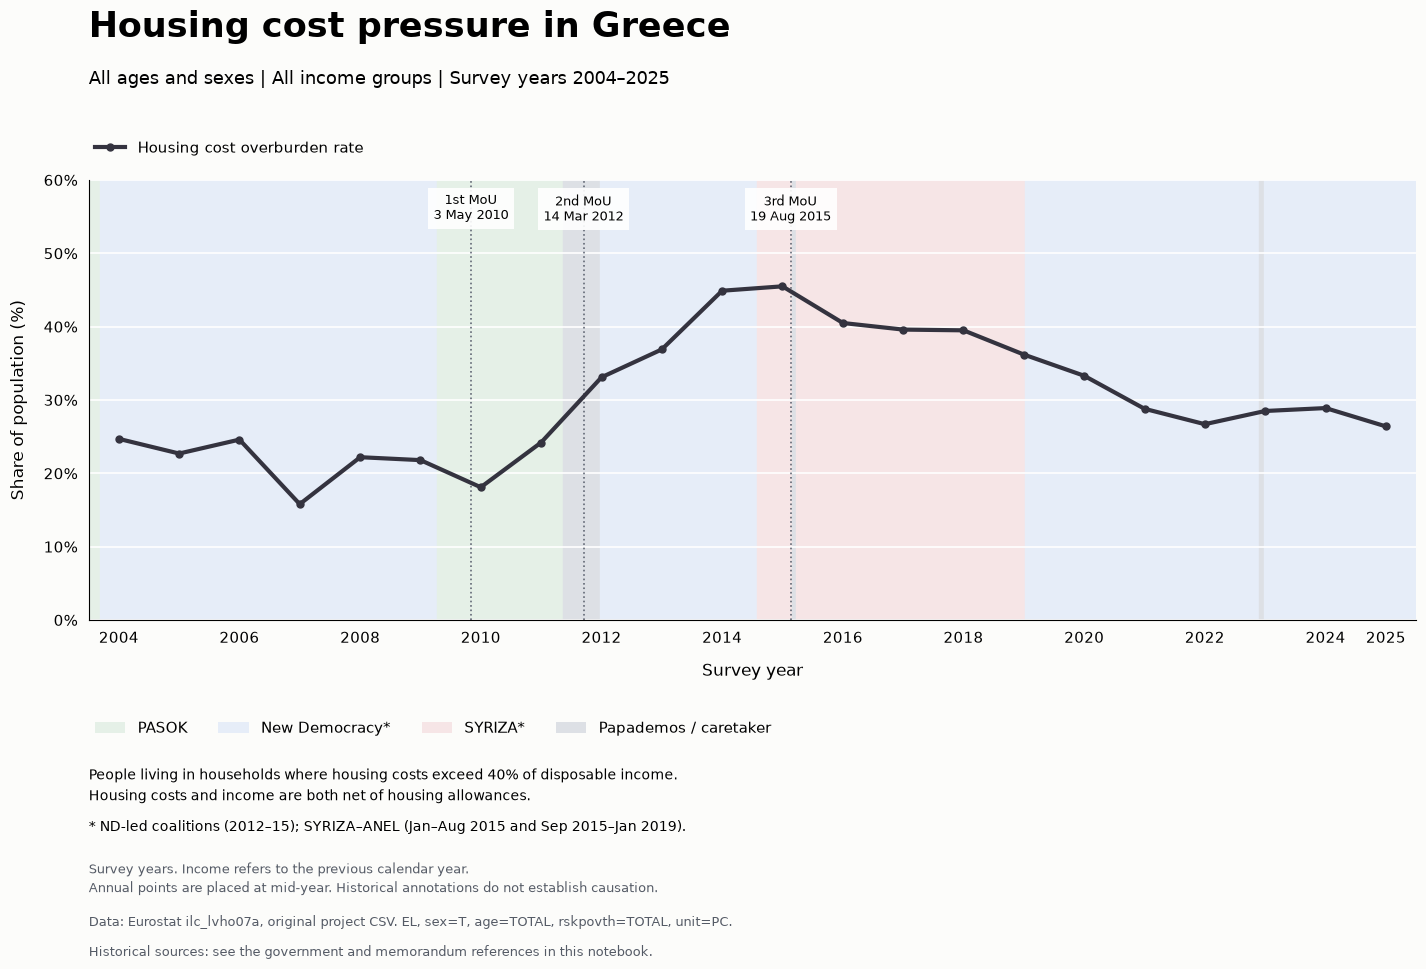

In [31]:
# Mid-year placement is a plotting convention, not a measurement date.
housing_dates = pd.to_datetime(housing_total["year"].astype(str) + "-07-01")

# Extend the local background periods to this chart's boundary.
housing_governments = government_periods.copy()
housing_governments[-1] = ("2023-06-26", "2026-01-01", "ND")

fig, ax = plt.subplots(figsize=(15, 10), facecolor="#FCFCFA")

# Reserve separate space for the title, legends and notes.
fig.subplots_adjust(left=0.08, right=0.965, top=0.80, bottom=0.36)

for start, end, party in housing_governments:
    ax.axvspan(
        pd.Timestamp(start), pd.Timestamp(end),
        color=background_colors[party],
        zorder=0)

ax.plot(
    housing_dates,
    housing_total["housing_overburden_rate"],
    color="#34333F",
    linestyle="-",
    linewidth=3,
    marker="o",
    markersize=5,
    label="Housing cost overburden rate",
    zorder=3)

for date, label in memoranda:
    date = pd.Timestamp(date)

    ax.axvline(
        date,
        color="#626875",
        linestyle=":",
        linewidth=1.2,
        zorder=2    )

    # Use the date horizontally and a fixed height within the axes.
    ax.text(
        date, 0.97, label,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.9
        },
        zorder=4)

# Include the latest year alongside the two-year ticks.
tick_years = list(range(2004, 2026, 2)) + [2025]
tick_dates = pd.to_datetime(
    [f"{year}-07-01" for year in tick_years])

ax.set_xticks(tick_dates)
ax.set_xticklabels(tick_years)
ax.set_xlim(
    pd.Timestamp("2004-01-01"),
    pd.Timestamp("2026-01-01"))

ax.set_ylim(0, 60)
ax.set_yticks(range(0, 61, 10))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

ax.set_xlabel("Survey year", fontsize=12, labelpad=12)
ax.set_ylabel("Share of population (%)", fontsize=12, labelpad=12)

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(axis="y", color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.04),
    borderaxespad=0,
    frameon=False,
    fontsize=11)

fig.suptitle(
    "Housing cost pressure in Greece",
    x=0.08, y=0.97,
    ha="left", va="top",
    fontsize=25,
    fontweight="bold")

# Top alignment makes the position of each text block predictable.
fig.text(
    0.08, 0.91,
    "All ages and sexes | All income groups | Survey years 2004–2025",
    va="top",
    fontsize=13)

fig.legend(
    handles=government_legend,
    loc="upper left",
    bbox_to_anchor=(0.08, 0.265),
    borderaxespad=0,
    ncol=4,
    frameon=False,
    fontsize=11)

fig.text(
    0.08, 0.215,
    "People living in households where housing costs exceed 40% "
    "of disposable income.\n"
    "Housing costs and income are both net of housing allowances.",
    va="top",
    fontsize=10,
    linespacing=1.5)

fig.text(
    0.08, 0.16,
    "* ND-led coalitions (2012–15); "
    "SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).",
    va="top",
    fontsize=10)

fig.text(
    0.08, 0.12,
    "Survey years. Income refers to the previous calendar year.\n"
    "Annual points are placed at mid-year. "
    "Historical annotations do not establish causation.",
    va="top",
    fontsize=9,
    linespacing=1.5,
    color="#555B66")

fig.text(
    0.08, 0.065,
    "Data: Eurostat ilc_lvho07a, original project CSV. "
    "EL, sex=T, age=TOTAL, rskpovth=TOTAL, unit=PC.",
    va="top",
    fontsize=9,
    color="#555B66")

fig.text(
    0.08, 0.035,
    "Historical sources: see the government and memorandum references "
    "in this notebook.",
    va="top",
    fontsize=9,
    color="#555B66")

# Save the completed figure before displaying it.
fig.savefig(
    "../reports/figures/greece_housing_cost_overburden.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Cities, Towns and suburbs, Rural areas

In [32]:
urban_data = pd.read_csv("../data/processed/ilc_di17_greece.csv")

In [33]:
urban_total = urban_data.loc[
    (urban_data["geo_code"] == "EL")
    & (urban_data["sex"] == "T")
    & (urban_data["age"] == "TOTAL")
    & (urban_data["unit"] == "EUR")
    & urban_data["indicator"].isin(["MEAN_EI", "MED_EI"]),
    [
        "year", "deg_urb", "Degree of urbanisation",
        "indicator", "income", "obs_flag"
    ]
].copy().sort_values(["deg_urb", "indicator", "year"])

In [34]:
# Keep the survey year and income reference year separately.
urban_total["income_year"] = urban_total["year"] - 1

In [35]:
# Check all six series against the available survey-year window.
urban_check = urban_total.pivot(
    index="year",
    columns=["deg_urb", "indicator"],
    values="income").reindex(range(2003, 2026))

print("Missing values or absent years per series:")
display(urban_check.isna().sum().rename("missing"))

print("Flagged observations:")
display(
    urban_total.loc[
        urban_total["obs_flag"].notna(),
        ["year", "income_year", "deg_urb", "indicator", "income", "obs_flag"]])

display(urban_check.tail())

Missing values or absent years per series:


deg_urb  indicator
DEG1     MEAN_EI      0
         MED_EI       0
DEG2     MEAN_EI      0
         MED_EI       0
DEG3     MEAN_EI      0
         MED_EI       0
Name: missing, dtype: int64

Flagged observations:


,year,income_year,deg_urb,indicator,income,obs_flag
9,2012,2011,DEG1,MEAN_EI,11508.0,b
492,2012,2011,DEG1,MED_EI,10381.0,b
32,2012,2011,DEG2,MEAN_EI,11682.0,b
515,2012,2011,DEG2,MED_EI,10091.0,b
55,2012,2011,DEG3,MEAN_EI,9360.0,b
538,2012,2011,DEG3,MED_EI,8340.0,b


deg_urb       DEG1              DEG2              DEG3         
indicator  MEAN_EI   MED_EI  MEAN_EI   MED_EI  MEAN_EI   MED_EI
year                                                           
2021       10666.0   9667.0  10508.0   9098.0   8501.0   7670.0
2022       11490.0  10147.0  11150.0   9760.0   9602.0   8327.0
2023       12144.0  10870.0  12021.0  10400.0  10152.0   8617.0
2024       13369.0  11800.0  12530.0  10950.0  10800.0   9407.0
2025       14362.0  12800.0  13355.0  11708.0  11847.0  10106.0

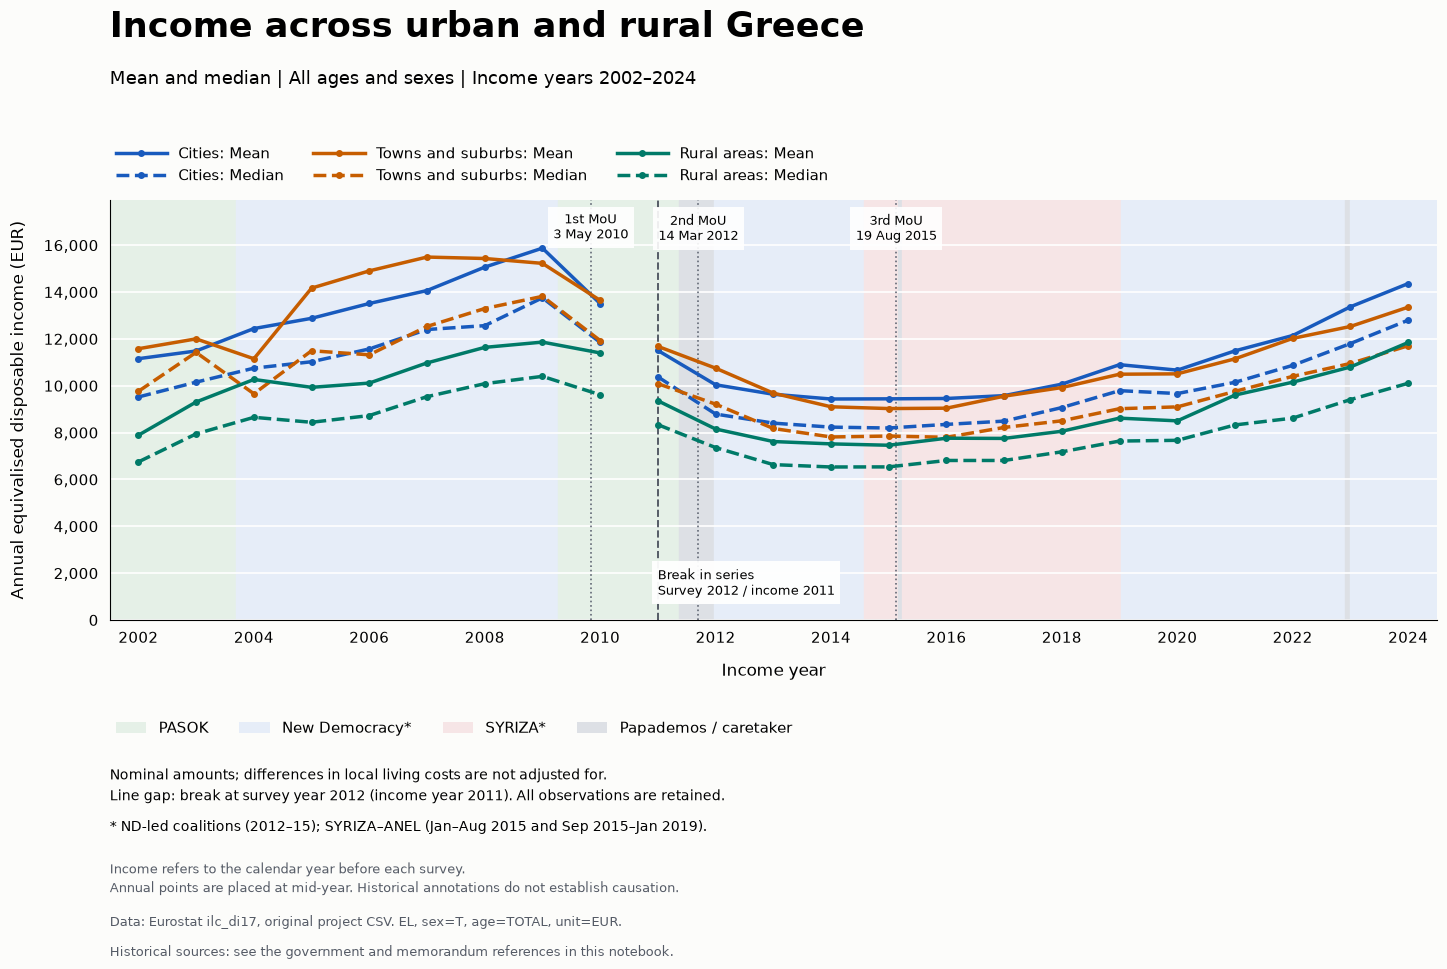

In [36]:
urban_plot = urban_total.sort_values("income_year").copy()

# Mid-year placement is a plotting convention, not a measurement date.
urban_plot["plot_date"] = pd.to_datetime(
    urban_plot["income_year"].astype(str) + "-07-01")

urban_groups = {
    "DEG1": ("Cities", "#185ABD"),
    "DEG2": ("Towns and suburbs", "#C65D00"),
    "DEG3": ("Rural areas", "#007A68")}

income_styles = {
    "MEAN_EI": ("Mean", "-"),
    "MED_EI": ("Median", "--")}

fig, ax = plt.subplots(figsize=(15, 10), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.08, right=0.965, top=0.78, bottom=0.36)

for start, end, party in government_periods:
    ax.axvspan(
        pd.Timestamp(start), pd.Timestamp(end),
        color=background_colors[party],
        zorder=0)

# Color identifies the area; line style identifies mean or median.
for area_code, (area_label, color) in urban_groups.items():
    for indicator, (income_label, style) in income_styles.items():

        series = urban_plot.loc[
            (urban_plot["deg_urb"] == area_code)
            & (urban_plot["indicator"] == indicator)]

        # Separate the two periods without removing any observations.
        before_break = series.loc[series["year"] < 2012]
        after_break = series.loc[series["year"] >= 2012]

        ax.plot(
            before_break["plot_date"],
            before_break["income"],
            color=color, linestyle=style,
            linewidth=2.5, marker="o", markersize=4,
            label=f"{area_label}: {income_label}",
            zorder=3)

        # No label here, so the legend lists each series only once.
        ax.plot(
            after_break["plot_date"],
            after_break["income"],
            color=color, linestyle=style,
            linewidth=2.5, marker="o", markersize=4,
            zorder=3)

for date, label in memoranda:
    date = pd.Timestamp(date)

    ax.axvline(
        date, color="#626875", linestyle=":",
        linewidth=1.2, zorder=2)

    ax.text(
        date, 0.97, label,
        transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.9
        }, zorder=4)

# Survey year 2012 corresponds to income reference year 2011.
break_date = pd.Timestamp("2011-07-01")

ax.axvline(
    break_date,
    color="#555B66",
    linestyle="--",
    linewidth=1.4,
    zorder=2)

# Place the break label below the income lines.
ax.text(
    break_date, 0.05,
    "Break in series\nSurvey 2012 / income 2011",
    transform=ax.get_xaxis_transform(),
    ha="left", va="bottom", fontsize=9,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.95
    }, zorder=4)

tick_years = list(range(2002, 2025, 2))
tick_dates = pd.to_datetime(
    [f"{year}-07-01" for year in tick_years])

ax.set_xticks(tick_dates)
ax.set_xticklabels(tick_years)
ax.set_xlim(
    pd.Timestamp("2002-01-01"),
    pd.Timestamp("2025-01-01"))

ax.margins(y=0.22)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.set_xlabel("Income year", fontsize=12, labelpad=12)
ax.set_ylabel(
    "Annual equivalised disposable income (EUR)",
    fontsize=12, labelpad=12)

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(axis="y", color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.025),
    borderaxespad=0,
    ncols=3,
    frameon=False,
    fontsize=10.5,
    handlelength=3.5)

fig.suptitle(
    "Income across urban and rural Greece",
    x=0.08, y=0.97,
    ha="left", va="top",
    fontsize=25, fontweight="bold")

fig.text(
    0.08, 0.91,
    "Mean and median | All ages and sexes | Income years 2002–2024",
    va="top", fontsize=13)

fig.legend(
    handles=government_legend,
    loc="upper left",
    bbox_to_anchor=(0.08, 0.265),
    borderaxespad=0,
    ncols=4,
    frameon=False,
    fontsize=11)

fig.text(
    0.08, 0.215,
    "Nominal amounts; differences in local living costs are not adjusted for.\n"
    "Line gap: break at survey year 2012 (income year 2011). "
    "All observations are retained.",
    va="top", fontsize=10, linespacing=1.5)

fig.text(
    0.08, 0.16,
    "* ND-led coalitions (2012–15); "
    "SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).",
    va="top", fontsize=10)

fig.text(
    0.08, 0.12,
    "Income refers to the calendar year before each survey.\n"
    "Annual points are placed at mid-year. "
    "Historical annotations do not establish causation.",
    va="top", fontsize=9,
    linespacing=1.5, color="#555B66")

fig.text(
    0.08, 0.065,
    "Data: Eurostat ilc_di17, original project CSV. "
    "EL, sex=T, age=TOTAL, unit=EUR.",
    va="top", fontsize=9, color="#555B66")

fig.text(
    0.08, 0.035,
    "Historical sources: see the government and memorandum references "
    "in this notebook.",
    va="top", fontsize=9, color="#555B66")

# Save the completed figure before displaying it.
fig.savefig(
    "../reports/figures/greece_income_by_urbanisation_mean_median.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

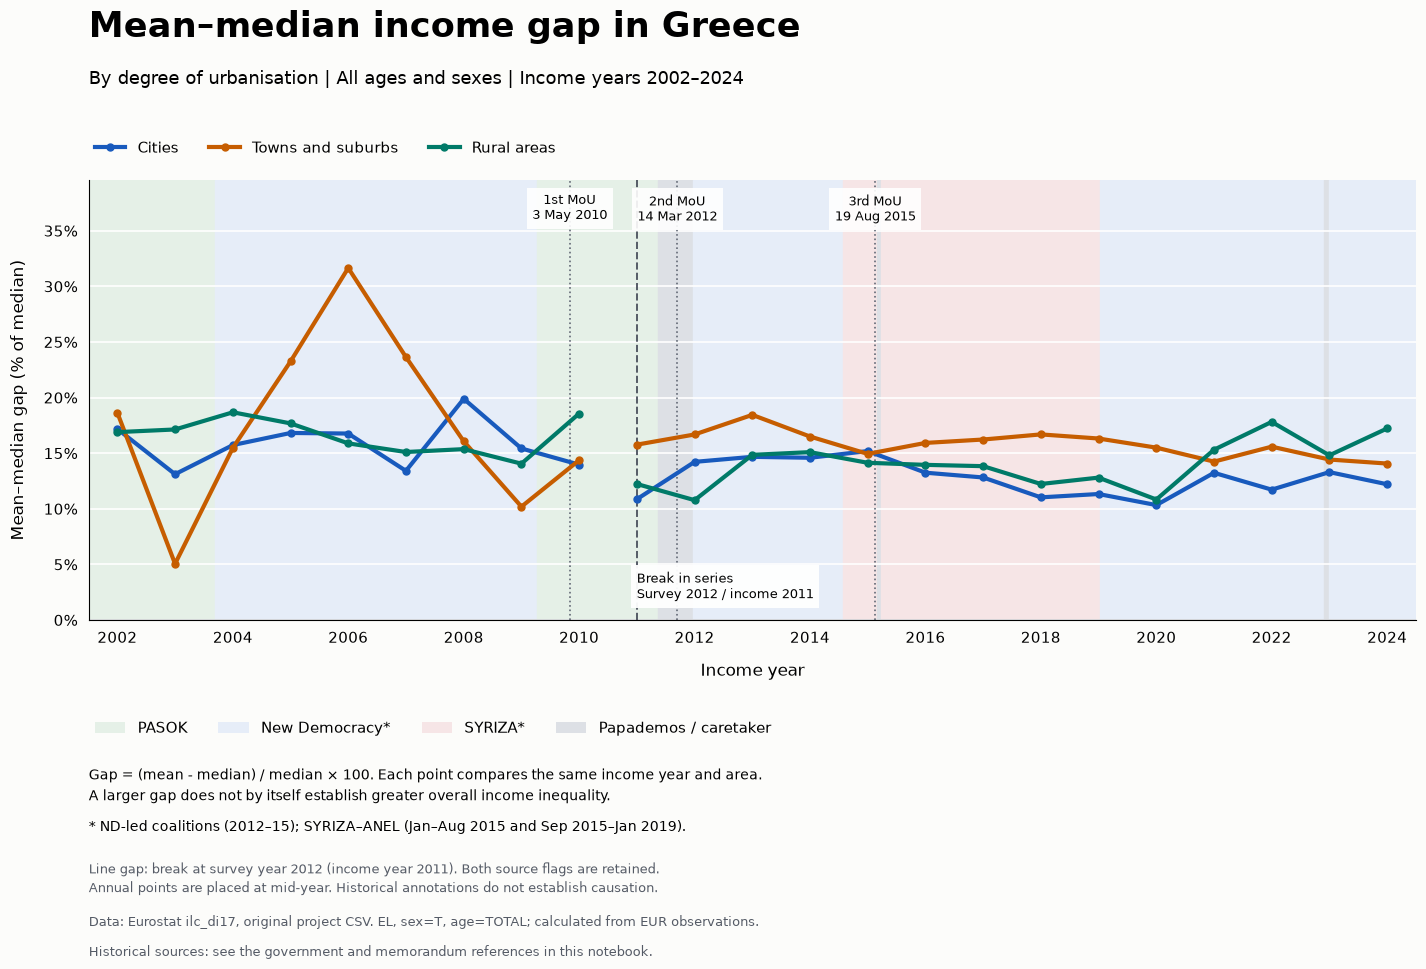

In [51]:
gap_index = ["year", "income_year", "deg_urb"]

# Place the published mean and median beside each other.
urban_gap = urban_total.pivot(
    index=gap_index,
    columns="indicator",
    values="income")

# Keep the observation flag of each source value.
urban_gap_flags = urban_total.pivot(
    index=gap_index,
    columns="indicator",
    values="obs_flag"
).rename(columns={
    "MEAN_EI": "mean_flag",
    "MED_EI": "median_flag"})

# Join values and flags using the same years and area category.
urban_gap = urban_gap.join(urban_gap_flags).reset_index()

# Express the difference as a percentage of the median.
urban_gap["gap_pct"] = (
    (urban_gap["MEAN_EI"] - urban_gap["MED_EI"])
    / urban_gap["MED_EI"]
    * 100)

urban_gap = urban_gap.sort_values(["deg_urb", "income_year"])

# Mid-year placement is a plotting convention.
urban_gap["plot_date"] = pd.to_datetime(
    urban_gap["income_year"].astype(str) + "-07-01")

fig, ax = plt.subplots(figsize=(15, 10), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.08, right=0.965, top=0.80, bottom=0.36)

for start, end, party in government_periods:
    ax.axvspan(
        pd.Timestamp(start), pd.Timestamp(end),
        color=background_colors[party],
        zorder=0)

# Reuse the area labels and colors from the previous chart.
for area_code, (area_label, color) in urban_groups.items():
    series = urban_gap.loc[urban_gap["deg_urb"] == area_code]

    # Keep every observation, but avoid connecting across the break.
    before_break = series.loc[series["year"] < 2012]
    after_break = series.loc[series["year"] >= 2012]

    ax.plot(
        before_break["plot_date"],
        before_break["gap_pct"],
        color=color, linewidth=3,
        marker="o", markersize=5,
        label=area_label,
        zorder=3)

    ax.plot(
        after_break["plot_date"],
        after_break["gap_pct"],
        color=color, linewidth=3,
        marker="o", markersize=5,
        zorder=3)

for date, label in memoranda:
    date = pd.Timestamp(date)

    ax.axvline(
        date, color="#626875", linestyle=":",
        linewidth=1.2, zorder=2)

    ax.text(
        date, 0.97, label,
        transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.9
        }, zorder=4)

break_date = pd.Timestamp("2011-07-01")

ax.axvline(
    break_date,
    color="#555B66", linestyle="--",
    linewidth=1.4, zorder=2)

ax.text(
    break_date, 0.04,
    "Break in series\nSurvey 2012 / income 2011",
    transform=ax.get_xaxis_transform(),
    ha="left", va="bottom", fontsize=9,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.95
    }, zorder=4)

tick_years = list(range(2002, 2025, 2))
tick_dates = pd.to_datetime([f"{year}-07-01" for year in tick_years])

ax.set_xticks(tick_dates)
ax.set_xticklabels(tick_years)
ax.set_xlim(
    pd.Timestamp("2002-01-01"),
    pd.Timestamp("2025-01-01"))

ax.axhline(0, color="#747985", linewidth=1, zorder=1)
ax.margins(y=0.25)

# Include zero without hiding any negative differences.
ax.set_ylim(bottom=min(0, urban_gap["gap_pct"].min() - 2))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

ax.set_xlabel("Income year", fontsize=12, labelpad=12)
ax.set_ylabel(
    "Mean–median gap (% of median)",
    fontsize=12, labelpad=12)

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(axis="y", color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.04),
    borderaxespad=0,
    ncols=3,
    frameon=False,
    fontsize=11)

fig.suptitle(
    "Mean–median income gap in Greece",
    x=0.08, y=0.97,
    ha="left", va="top",
    fontsize=25, fontweight="bold")

fig.text(
    0.08, 0.91,
    "By degree of urbanisation | All ages and sexes | Income years 2002–2024",
    va="top", fontsize=13)

fig.legend(
    handles=government_legend,
    loc="upper left",
    bbox_to_anchor=(0.08, 0.265),
    borderaxespad=0,
    ncols=4,
    frameon=False,
    fontsize=11)

fig.text(
    0.08, 0.215,
    "Gap = (mean - median) / median × 100. "
    "Each point compares the same income year and area.\n"
    "A larger gap does not by itself establish greater overall income inequality.",
    va="top", fontsize=10, linespacing=1.5)

fig.text(
    0.08, 0.16,
    "* ND-led coalitions (2012–15); "
    "SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).",
    va="top", fontsize=10)

fig.text(
    0.08, 0.12,
    "Line gap: break at survey year 2012 (income year 2011). "
    "Both source flags are retained.\n"
    "Annual points are placed at mid-year. "
    "Historical annotations do not establish causation.",
    va="top", fontsize=9,
    linespacing=1.5, color="#555B66")

fig.text(
    0.08, 0.065,
    "Data: Eurostat ilc_di17, original project CSV. "
    "EL, sex=T, age=TOTAL; calculated from EUR observations.",
    va="top", fontsize=9, color="#555B66")

fig.text(
    0.08, 0.035,
    "Historical sources: see the government and memorandum references "
    "in this notebook.",
    va="top", fontsize=9, color="#555B66")

# Save the completed figure before displaying it.
fig.savefig(
    "../reports/figures/greece_mean_median_gap_by_urbanisation.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Greece: closing notes

Mean and median income fell between 2009 and 2015, then recovered. By 2024, both remained below their 2009 levels after adjusting for inflation. Recovery differed across age groups, while cities recorded higher income levels than rural areas in 2024.

Housing cost overburden declined from its 2015 peak, but this alone does not establish improved housing affordability.

The next notebook compares Greece with other European countries.